# Project 18: Time-Series Forecasting & Fourier Spectral Analysis

This project analyzes multi-seasonal time-series signals using Fourier Transform feature extraction
and trains an autoregressive neural forecaster using NeuroGebra `ModelBuilder`.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from neurogebra.builders.model_builder import ModelBuilder

np.random.seed(42)
# Generate synthetic time series with trend, 2 seasonal cycles, and noise
N_POINTS = 500
t = np.linspace(0, 50, N_POINTS)
signal = 0.05 * t + np.sin(t) + 0.5 * np.sin(3 * t) + np.random.normal(0, 0.15, N_POINTS)
print(f'[INFO] Generated {len(signal)} time-series data points.')


[INFO] Generated 500 time-series data points.


<string>:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


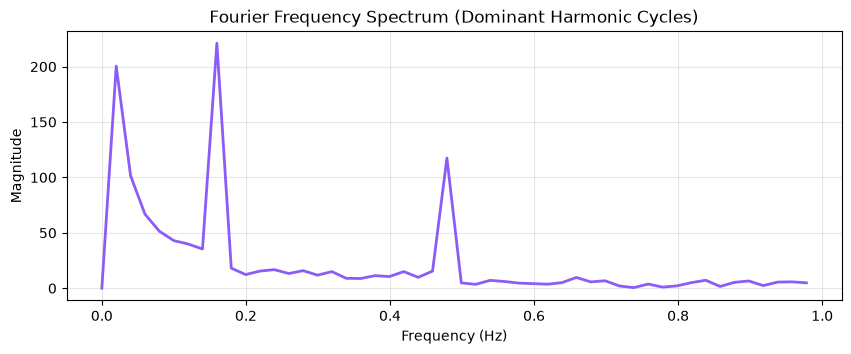

In [2]:
# Fast Fourier Transform (FFT) Frequency Analysis
fft_vals = np.fft.rfft(signal - np.mean(signal))
fft_freqs = np.fft.rfftfreq(N_POINTS, d=(t[1] - t[0]))
fft_mag = np.abs(fft_vals)

plt.figure(figsize=(10, 3.5))
plt.plot(fft_freqs[:50], fft_mag[:50], color='#8b5cf6', lw=2)
plt.title('Fourier Frequency Spectrum (Dominant Harmonic Cycles)')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.grid(True, alpha=0.3)
plt.show()


In [3]:
# Autoregressive windowing dataset
WINDOW_SIZE = 12
X, y = [], []
for i in range(len(signal) - WINDOW_SIZE):
    X.append(signal[i:i + WINDOW_SIZE])
    y.append(signal[i + WINDOW_SIZE])
X = np.array(X)
y = np.array(y).reshape(-1, 1)

split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

builder = ModelBuilder()
forecaster = builder.Sequential([
    builder.Dense(32, activation='relu'),
    builder.Dense(16, activation='relu'),
    builder.Dense(1, activation='linear'),
], name='TimeSeriesForecaster')
forecaster.compile(loss='mse', optimizer='adam', learning_rate=0.005)
forecaster.fit(X_train, y_train, epochs=8, batch_size=16, validation_split=0.1)
print('[SUCCESS] Forecaster trained.')



Compiling model...
   Loss: mse
   Optimizer: adam (lr=0.005)
   Metrics: accuracy
   Model compiled successfully.


 Training TimeSeriesForecaster...

   Training samples: 390
   Epochs: 8
   Batch size: 16


Execution plan:

1.  The model will see 351 training examples
    It learns patterns by adjusting its weights

2.  This process repeats 8 times (epochs)
    Each time, the model gets better at predictions

3.  After each epoch, we test on 39 validation examples
    This tells us if the model is learning or just memorizing

Let's begin.


  Epoch   1/8 ███░░░░░░░░░░░░░░░░░░░░░░░░░░░ loss: 0.2509 - acc: 0.6119 - val_loss: 0.1034 - val_acc: 0.1795 - 0.0s
  Epoch   2/8 ███████░░░░░░░░░░░░░░░░░░░░░░░ loss: 0.0872 - acc: 0.6383 - val_loss: 0.0932 - val_acc: 0.1795 - 0.0s
  Epoch   3/8 ███████████░░░░░░░░░░░░░░░░░░░ loss: 0.0586 - acc: 0.6661 - val_loss: 0.0744 - val_acc: 0.1795 - 0.0s
  Epoch   4/8 ███████████████░░░░░░░░░░░░░░░ loss: 0.0546 - acc: 0.6638 - val_loss: 0.0711 - val_acc:

<string>:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


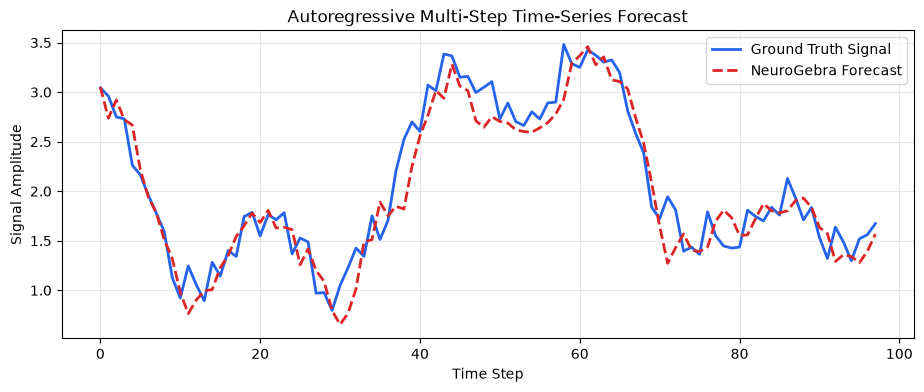

In [4]:
preds = forecaster.predict(X_test)
plt.figure(figsize=(11, 4))
plt.plot(range(len(y_test)), y_test, label='Ground Truth Signal', color='#2563eb', lw=2)
plt.plot(range(len(preds)), preds, label='NeuroGebra Forecast', color='#dc2626', lw=2, linestyle='--')
plt.title('Autoregressive Multi-Step Time-Series Forecast')
plt.xlabel('Time Step')
plt.ylabel('Signal Amplitude')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
